# One-to-one (1:1) binding: multi-cycle kinetics (MCK)

Parameter-recovery benchmark. This notebook is AI generated.

The data are simulated from the rate equations written below, integrated with SciPy (`solve_ivp`, Radau). No pykingenie function is used to make the data. The data are then fitted with pykingenie, using one Smax (Rmax) shared by all curves, and the fitted parameters are compared with the true ones. A parameter counts as recovered when its relative error is at most 5%.

Gaussian noise with a standard deviation of 0.1 RU is added (Rmax = 50 RU).


## Model

$$A + L \underset{k_{off}}{\overset{k_{on}}{\rightleftharpoons}} AL$$

$A$ is the analyte (concentration $C$), $L$ the immobilised ligand, and $R$ the signal of $AL$:

$$\frac{dR}{dt} = k_{on}\,C\,(R_{max} - R) - k_{off}\,R, \qquad \text{signal} = R$$

pykingenie reports `Kd [µM]` (= k_off / k_on), `k_off [1/s]` and `Smax` (= $R_{max}$).

In [1]:
import sys

import numpy as np

sys.path.insert(0, '..')
from benchmark_helpers import simulate_mck, compare_parameters, plot_fit
from pykingenie.fitter_surface import KineticsFitter

## True parameters and experiment design

Each concentration is injected on a regenerated (free) surface for 300 s, followed by 600 s of buffer. Sampling every 1 s.

In [2]:
params = dict(kon=1.0, koff=0.01, Rmax=50.0)  # kon in 1/(µM·s), koff in 1/s, Rmax in RU
concs = [0.0011, 0.0033, 0.01, 0.03, 0.09, 0.27]  # µM, Kd = 0.01 µM

true_values = {'Kd': params['koff'] / params['kon'], 'k_off': params['koff'], 'Smax': params['Rmax']}

## Rate equations (first principles)

In [3]:
def rhs(t, y, conc, p):
    R = y[0]
    return [p['kon'] * conc * (p['Rmax'] - R) - p['koff'] * R]


def signal(y, p):
    return y[:, 0]


y0 = [0.0]

## Simulate the data

In [4]:
data = simulate_mck(rhs, signal, y0, params, concs, assoc_time=300.0, disso_time=600.0, dt=1.0,
                    noise_sd=0.1, seed=0)

## Fit with pykingenie

One Smax shared by all curves (`smax_id` is 0 for every curve).

In [5]:
fitter = KineticsFitter(
    time_assoc_lst=data['time_assoc'], association_signal_lst=data['assoc'],
    lig_conc_lst=concs,
    time_diss_lst=data['time_disso'], dissociation_signal_lst=data['disso'],
    smax_id=[0] * len(concs), name_lst=['benchmark'], is_single_cycle=False,
)
fitter.get_steady_state()
fitter.fit_steady_state()  # starting value of Kd
fitter.fit_one_site_assoc_and_disso(shared_smax=True)
fitter.fit_params_kinetics

,Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s]
0,0.010009,0.009999,50.010391,0.999074


## Compare with the true parameters

In [6]:
fitted_values = {'Kd': fitter.Kd, 'k_off': fitter.k_off, 'Smax': fitter.Smax[0]}

comparison = compare_parameters(true_values, fitted_values, rtol=0.05)
worst = comparison['rel. error (%)'].abs().idxmax()
print(f"All parameters recovered within 5%: {comparison['recovered'].all()}. "
      f"Largest error: {comparison.loc[worst, 'rel. error (%)']:+.2f}% ({worst})")
comparison

All parameters recovered within 5%: True. Largest error: +0.09% (Kd)


,true,fitted,rel. error (%),recovered
parameter,,,,
Kd,0.01,0.010009,0.086026,True
k_off,0.01,0.009999,-0.006632,True
Smax,50.00,50.010391,0.020783,True


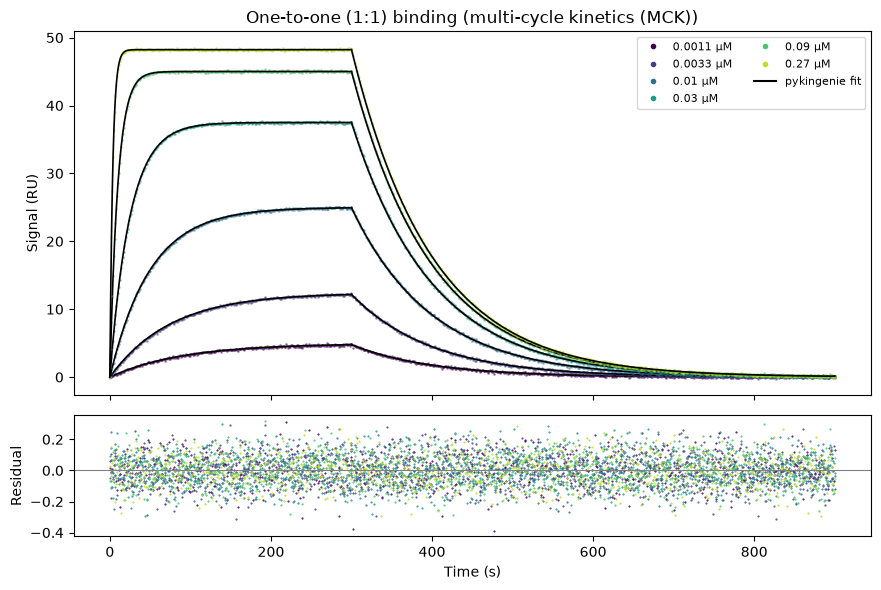

In [7]:
fig = plot_fit(data, fitter, concs, 'One-to-one (1:1) binding (multi-cycle kinetics (MCK))')